In [1]:
import sys

sys.path.insert(0, "../src")


import json
from datetime import datetime
from pathlib import Path

import modal
import torch
import torch.nn as nn
from core import Method, train
from IPython.display import Image, display
from model import CondEmbedderSigmaAndJump, ShortcutModel
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from unet import Unet

In [2]:
class ShortcutFlow(Method):
    def __init__(
        self,
        shortcut_frac: float,
        step_fracs: tuple[float, ...],
        img_shape: tuple[int, int, int],
    ):
        # Steps should be 1, ..., 1/32, the finest half step 1/64 is flow matching
        self.shortcut_frac, self.step_fracs = shortcut_frac, step_fracs
        self.img_shape = img_shape

    def loss(
        self, model: nn.Module, ema: nn.Module, imgs: torch.Tensor
    ) -> dict[str, torch.Tensor]:
        assert isinstance(model, ShortcutModel)

        batches = imgs.shape[0]
        device = imgs.device
        num_short = int(self.shortcut_frac * batches)
        noise = torch.randn_like(imgs)

        # Shortcut portion
        # Remember to keep t on the discretized grid
        jump_short = torch.tensor(self.step_fracs, device=device)[
            torch.randint(
                low=0, high=len(self.step_fracs), size=(num_short,), device=device
            )
        ]

        imgs_short = imgs[:num_short]
        t_short = (
            torch.rand(num_short, device=device) / jump_short
        ).floor() * jump_short

        x_short = (
            t_short[:, None, None, None] * imgs_short
            + (1 - t_short)[:, None, None, None] * noise[:num_short]
        )

        with torch.no_grad():
            # Note: the EMA predicts D, converted to v to take the half steps
            d_1 = ema(x_short, t_short, jump_short / 2)
            v_1 = (d_1 - x_short) / (1 - t_short)[:, None, None, None]
            x_mid = (x_short + v_1 * jump_short[:, None, None, None] / 2).clamp(-4, +4)

            t_mid = t_short + jump_short / 2
            d_2 = ema(x_mid, t_mid, jump_short / 2)
            v_2 = (d_2 - x_mid) / (1 - t_mid)[:, None, None, None]

            # Follow the paper when we clamp
            v_target = ((v_1 + v_2) / 2).clamp(-4, +4)

            # Back to D-space
            target_short = x_short + (1 - t_short)[:, None, None, None] * v_target

        # Flow matching
        flow_grid_step = min(self.step_fracs) / 2

        t_flow = (
            torch.rand(batches - num_short, device=device) / flow_grid_step
        ).floor() * flow_grid_step

        x_flow = (
            t_flow[:, None, None, None] * imgs[num_short:]
            + (1 - t_flow)[:, None, None, None] * noise[num_short:]
        )
        target_flow = imgs[num_short:]

        # Combining the two
        t = torch.cat([t_short, t_flow], dim=0)
        out = model(
            torch.cat([x_short, x_flow], dim=0),
            t,
            torch.cat([jump_short, torch.zeros(x_flow.shape[0], device=device)]),
        )
        target = torch.cat([target_short, target_flow])

        # Dreamer 4's ramp weight
        sq_error_per = ((out - target) ** 2).mean(dim=(1, 2, 3))
        loss = ((0.9 * t + 0.1) * sq_error_per).mean()

        return {"loss": loss, "report": sq_error_per.mean().detach()}

    @torch.no_grad()
    def sample(self, model: nn.Module, num_samples: int, steps: int) -> torch.Tensor:
        assert 1 / steps in self.step_fracs

        device = next(model.parameters()).device
        jump = torch.full((num_samples,), 1 / steps, device=device)

        x = torch.randn((num_samples, *self.img_shape), device=device)

        for i in range(steps):
            t = torch.full((num_samples,), i / steps, device=device)
            v = (model(x, t, jump) - x) / (1 - t)[:, None, None, None]
            x = x + v / steps

        return x

In [3]:
transform = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5)),
    ]
)
dataset = datasets.CIFAR10(
    root="./data", train=True, download=True, transform=transform
)
sigma_data: float = 0.5031378865242004

In [4]:
unet = Unet(
    inp_ch=3,
    inp_proj_ch=64,
    midcoder_ch=64,
    enc_dec_channels=(64, 64, 64, 64),
    out_ch=3,
    group_size=32,
    cond_dim=256,
    num_heads=8,
)
step_fracs = (1.0, 1 / 2, 1 / 4, 1 / 8, 1 / 16, 1 / 32)

# Note: t spans [0, 1] instead of the ~[-1.6, 1.1] of 0.25 * ln(sigma)
embedder = CondEmbedderSigmaAndJump(
    cond_dim=256, w_min_sigma=0.5, w_max_sigma=40.0, num_jumps=len(step_fracs)
)

flow_model = ShortcutModel(unet, embedder)


shortcut_method = ShortcutFlow(
    shortcut_frac=0.25,
    step_fracs=step_fracs,
    img_shape=(3, 32, 32),
)

In [5]:
app = modal.App("shortcut-dreamer")

image = (
    modal.Image.debian_slim(python_version="3.13")
    .uv_sync(uv_project_dir="../../..", extra_options="--no-dev")
    .add_local_python_source("model", "emb", "unet", "core")
)
data_volume = modal.Volume.from_name("exp-diffusion-cfar", create_if_missing=True)

In [6]:
@app.function(
    image=image,
    gpu="H100",
    timeout=4 * 60 * 60,
    volumes={"/data": data_volume},
    serialized=True,
)
def run(model: nn.Module, method: Method, run_name: str):
    loader = DataLoader(
        datasets.CIFAR10(root="/data", train=True, download=True, transform=transform),
        batch_size=512,
        shuffle=True,
        num_workers=4,
        persistent_workers=True,
    )
    run_dir = Path("/data/runs") / run_name
    run_dir.mkdir(parents=True, exist_ok=True)

    for row, png in train(
        model,
        method,
        loader,
        epochs=500,
        eval_every=50,
        lr=1e-3,
        min_lr=1e-5,
        warmup_steps=1000,
        weight_decay=1e-2,
        ema_decay=0.999,
        fid_batches=2,
        fid_batch_size=5120,
        fid_chunk_size=512,
    ):
        # Note: Modal commits the volume in the background every few seconds, so the
        # metrics survive the client disconnecting
        with open(run_dir / "metrics.jsonl", "a") as f:
            f.write(json.dumps(row) + "\n")
        yield row, png

epoch 0 | loss 0.1177 | train 9s


epoch 1 | loss 0.0603 | train 8s


epoch 2 | loss 0.0541 | train 8s


epoch 3 | loss 0.0515 | train 8s


epoch 4 | loss 0.0512 | train 8s


...

epoch 45 | loss 0.0455 | train 8s


epoch 46 | loss 0.0453 | train 8s


epoch 47 | loss 0.0453 | train 8s


epoch 48 | loss 0.0459 | train 8s


epoch 49 | loss 0.0457 | train 8s
  FID 1: 97.5  2: 87.8  4: 80.6  8: 74.7  16: 69.9  32: 65.8 | 37s


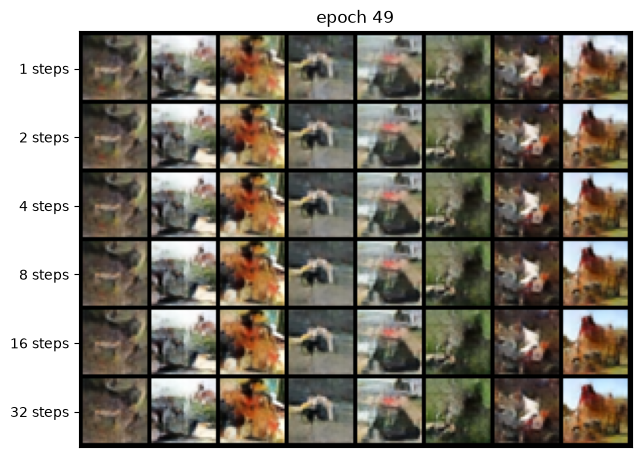

epoch 50 | loss 0.0459 | train 8s


epoch 51 | loss 0.0457 | train 8s


epoch 52 | loss 0.0454 | train 8s


epoch 53 | loss 0.0452 | train 8s


epoch 54 | loss 0.0453 | train 8s


...

epoch 95 | loss 0.0448 | train 8s


epoch 96 | loss 0.0454 | train 8s


epoch 97 | loss 0.0443 | train 8s


epoch 98 | loss 0.0449 | train 7s


epoch 99 | loss 0.0449 | train 8s
  FID 1: 81.7  2: 68.9  4: 61.3  8: 56.0  16: 51.4  32: 49.3 | 37s


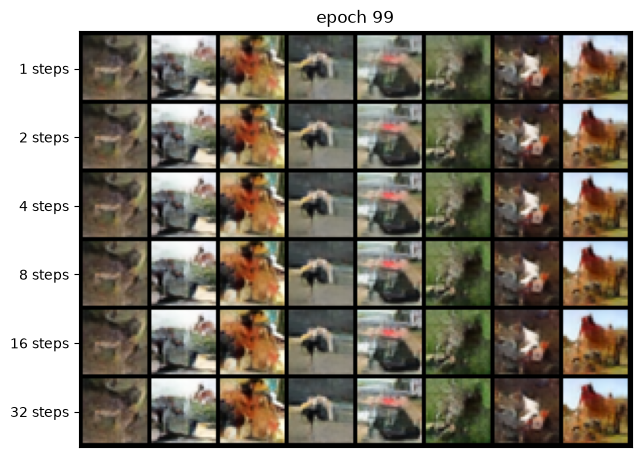

epoch 100 | loss 0.0449 | train 8s


epoch 101 | loss 0.0452 | train 8s


epoch 102 | loss 0.0448 | train 8s


epoch 103 | loss 0.0450 | train 8s


epoch 104 | loss 0.0448 | train 8s


...

epoch 145 | loss 0.0448 | train 8s


epoch 146 | loss 0.0449 | train 8s


epoch 147 | loss 0.0444 | train 8s


epoch 148 | loss 0.0447 | train 8s


epoch 149 | loss 0.0444 | train 8s
  FID 1: 71.3  2: 56.4  4: 50.4  8: 46.3  16: 42.9  32: 41.6 | 36s


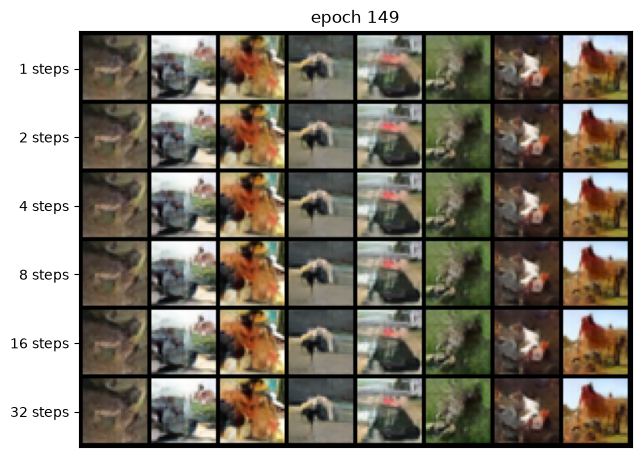

epoch 150 | loss 0.0447 | train 8s


epoch 151 | loss 0.0444 | train 8s


epoch 152 | loss 0.0446 | train 8s


epoch 153 | loss 0.0440 | train 8s


epoch 154 | loss 0.0447 | train 8s


...

epoch 195 | loss 0.0446 | train 8s


epoch 196 | loss 0.0441 | train 8s


epoch 197 | loss 0.0447 | train 8s


epoch 198 | loss 0.0447 | train 8s


epoch 199 | loss 0.0444 | train 8s
  FID 1: 64.1  2: 49.0  4: 44.1  8: 40.9  16: 38.2  32: 37.1 | 35s


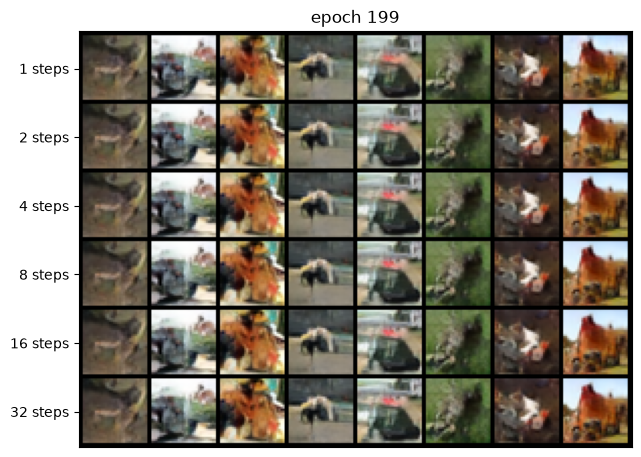

epoch 200 | loss 0.0443 | train 8s


epoch 201 | loss 0.0441 | train 8s


epoch 202 | loss 0.0449 | train 8s


epoch 203 | loss 0.0443 | train 7s


epoch 204 | loss 0.0442 | train 8s


...

epoch 245 | loss 0.0441 | train 8s


epoch 246 | loss 0.0444 | train 7s


epoch 247 | loss 0.0443 | train 7s


epoch 248 | loss 0.0441 | train 7s


epoch 249 | loss 0.0442 | train 7s
  FID 1: 59.3  2: 44.9  4: 40.8  8: 37.9  16: 36.5  32: 35.4 | 35s


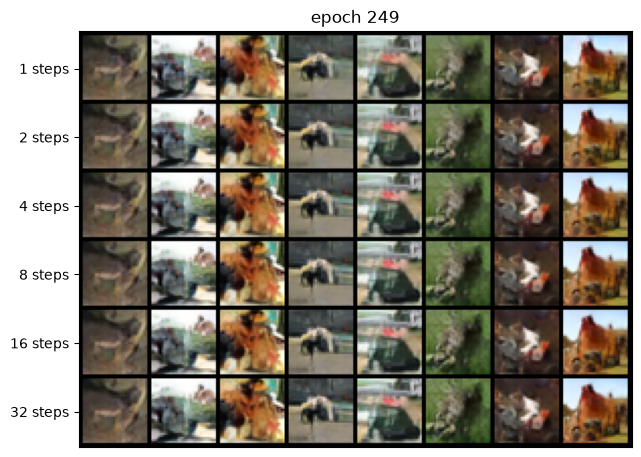

epoch 250 | loss 0.0441 | train 7s


epoch 251 | loss 0.0441 | train 7s


epoch 252 | loss 0.0441 | train 7s


epoch 253 | loss 0.0440 | train 8s


epoch 254 | loss 0.0445 | train 8s


...

epoch 295 | loss 0.0436 | train 8s


epoch 296 | loss 0.0443 | train 8s


epoch 297 | loss 0.0441 | train 8s


epoch 298 | loss 0.0441 | train 8s


epoch 299 | loss 0.0440 | train 8s
  FID 1: 57.0  2: 42.7  4: 39.1  8: 36.6  16: 34.7  32: 33.7 | 36s


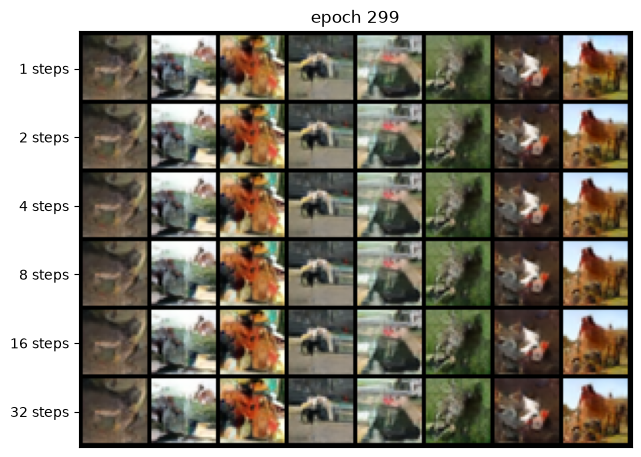

epoch 300 | loss 0.0438 | train 8s


epoch 301 | loss 0.0440 | train 8s


epoch 302 | loss 0.0440 | train 8s


epoch 303 | loss 0.0438 | train 8s


epoch 304 | loss 0.0435 | train 8s


...

epoch 345 | loss 0.0435 | train 8s


epoch 346 | loss 0.0441 | train 8s


epoch 347 | loss 0.0437 | train 8s


epoch 348 | loss 0.0438 | train 8s


epoch 349 | loss 0.0437 | train 8s
  FID 1: 54.4  2: 40.5  4: 37.7  8: 35.5  16: 34.9  32: 33.4 | 36s


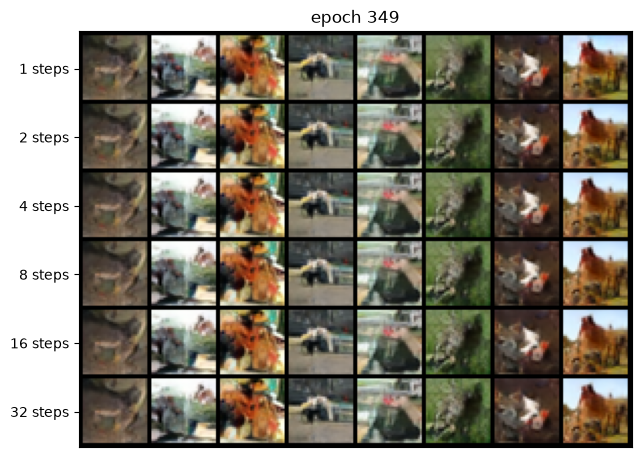

epoch 350 | loss 0.0445 | train 8s


epoch 351 | loss 0.0442 | train 8s


epoch 352 | loss 0.0436 | train 8s


epoch 353 | loss 0.0436 | train 8s


epoch 354 | loss 0.0440 | train 8s


...

epoch 395 | loss 0.0437 | train 8s


epoch 396 | loss 0.0437 | train 8s


epoch 397 | loss 0.0436 | train 8s


epoch 398 | loss 0.0436 | train 8s


epoch 399 | loss 0.0439 | train 8s
  FID 1: 53.9  2: 39.9  4: 37.3  8: 35.6  16: 33.8  32: 33.3 | 36s


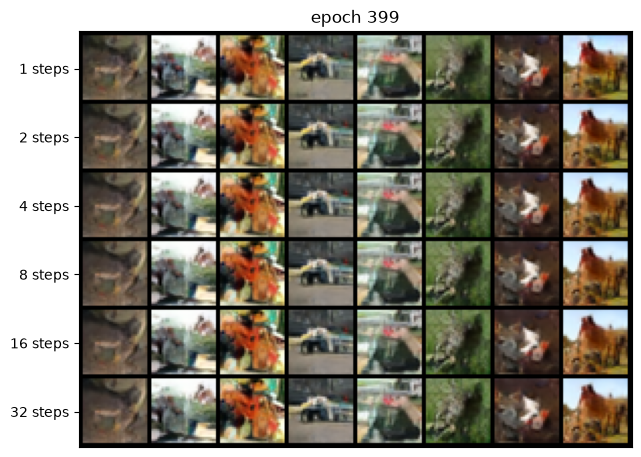

epoch 400 | loss 0.0438 | train 8s


epoch 401 | loss 0.0443 | train 8s


epoch 402 | loss 0.0438 | train 8s


epoch 403 | loss 0.0436 | train 8s


epoch 404 | loss 0.0430 | train 8s


...

epoch 445 | loss 0.0436 | train 8s


epoch 446 | loss 0.0437 | train 8s


epoch 447 | loss 0.0434 | train 8s


epoch 448 | loss 0.0437 | train 8s


epoch 449 | loss 0.0443 | train 8s
  FID 1: 52.7  2: 40.6  4: 37.1  8: 35.3  16: 34.0  32: 32.8 | 36s


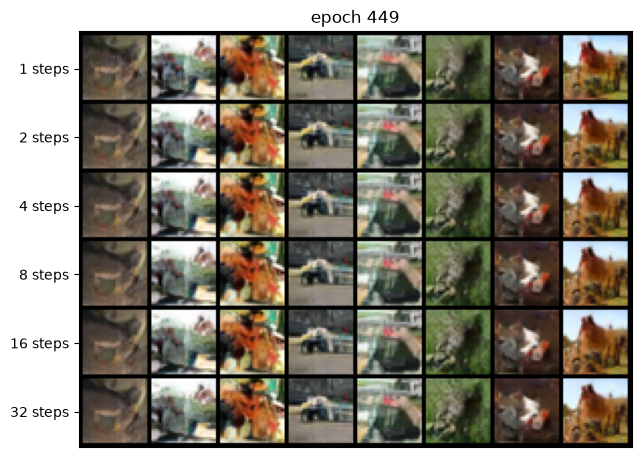

epoch 450 | loss 0.0437 | train 8s


epoch 451 | loss 0.0440 | train 8s


epoch 452 | loss 0.0433 | train 8s


epoch 453 | loss 0.0435 | train 8s


epoch 454 | loss 0.0431 | train 8s


...

epoch 495 | loss 0.0437 | train 8s


epoch 496 | loss 0.0435 | train 8s


epoch 497 | loss 0.0434 | train 8s


epoch 498 | loss 0.0437 | train 8s


epoch 499 | loss 0.0437 | train 8s
  FID 1: 51.9  2: 40.0  4: 36.2  8: 35.0  16: 33.4  32: 32.7 | 36s


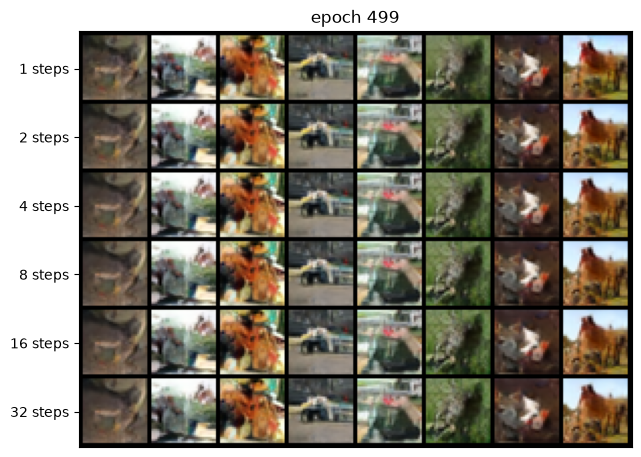

In [7]:
results_dir = Path("results") / f"shortcut-dreamer-{datetime.now():%Y%m%d-%H%M%S}"
(results_dir / "samples").mkdir(parents=True)

# Note: detached so the run keeps going if the client disconnects, stop it with
# modal app stop <app id>
with app.run(detach=True):
    for row, png in run.remote_gen(flow_model, shortcut_method, results_dir.name):
        with open(results_dir / "metrics.jsonl", "a") as f:
            f.write(json.dumps(row) + "\n")
        print(
            f"epoch {row['epoch']} | loss {row['loss']:.4f}"
            f" | train {row['train_sec']:.0f}s"
        )

        # FID and samples only come with eval epochs
        if png is not None:
            fid_str = "  ".join(
                f"{steps}: {value:.1f}" for steps, value in row["fid"].items()
            )
            print(f"  FID {fid_str} | {row['fid_sec']:.0f}s")
            (results_dir / "samples" / f"epoch_{row['epoch']:03d}.png").write_bytes(png)
            display(Image(data=png))